# PulmoSight 01 — Data Exploration & Leak-Free Splits

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


## 1. Dataset inventory

C:\Users\Veer Pratap Singh\AppData\Local\Temp\ipykernel_28236\3620553045.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  counts["total"] = counts.sum(1)


class,normal,tb,total,tb_share
folder,,,,
train,6860,6585,13445,0.49
val,1715,1647,3362,0.49


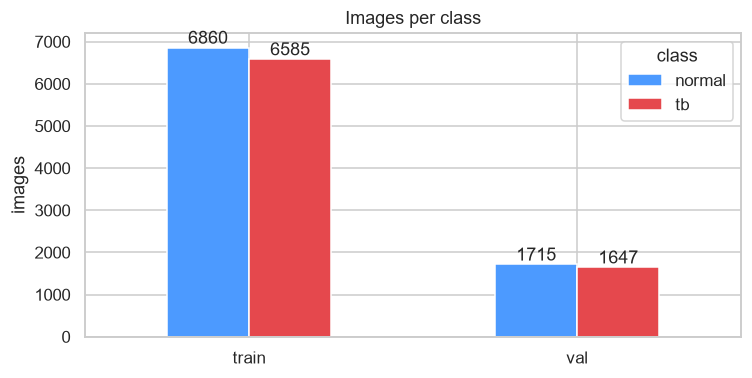

In [2]:
rows = []
for split in ["train", "val"]:
    for label, cls in enumerate(CLASSES):
        for f in sorted((ROOT / "data" / "cache512" / split / cls).glob("*.png")):
            rows.append({"path": f.relative_to(ROOT).as_posix(), "folder": split, "class": cls, "label": label})
data = pd.DataFrame(rows)
counts = data.groupby(["folder", "class"]).size().unstack()
counts["total"] = counts.sum(1)
counts["tb_share"] = (counts["tb"] / counts["total"]).round(3)
display(counts)

fig, ax = plt.subplots(figsize=(7, 3.6))
counts[CLASSES].plot.bar(ax=ax, color=["#4C9AFF", "#E5484D"], rot=0)
ax.set(title="Images per class", ylabel="images", xlabel="")
for c in ax.containers: ax.bar_label(c, fmt="%d")
plt.tight_layout(); plt.show()

## 2. Original resolutions

            w       h
count  1500.0  1500.0
mean    512.0   512.0
std       0.0     0.0
min     512.0   512.0
25%     512.0   512.0
50%     512.0   512.0
75%     512.0   512.0
max     512.0   512.0

Modes: {'RGB': 1500} | Extensions: {'.jpg': 1500}


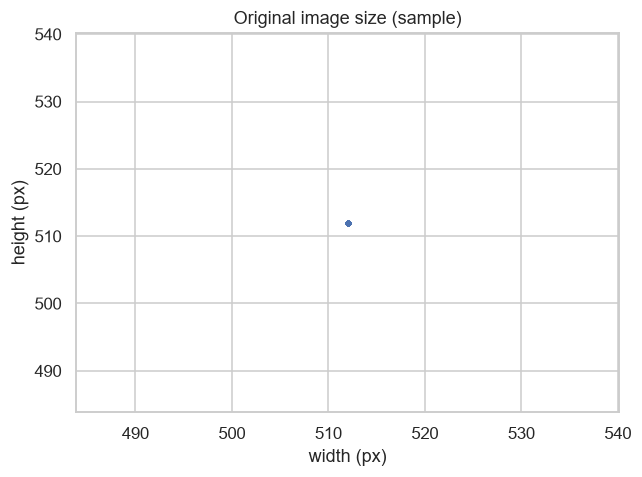

In [3]:
from PIL import Image
originals = [p for p in (ROOT / "data" / "raw" / "train").rglob("*") if p.suffix.lower() in {".png", ".jpg", ".jpeg"}]
sample = random.Random(SEED).sample(originals, min(1500, len(originals)))
sizes = []
for p in sample:
    with Image.open(p) as im:
        sizes.append({"w": im.width, "h": im.height, "mode": im.mode, "ext": p.suffix.lower()})
sizes = pd.DataFrame(sizes)
print(sizes.describe().round(0))
print("\nModes:", sizes["mode"].value_counts().to_dict(), "| Extensions:", sizes["ext"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(sizes.w, sizes.h, s=6, alpha=0.4)
ax.set(title="Original image size (sample)", xlabel="width (px)", ylabel="height (px)")
plt.tight_layout(); plt.show()

## 3. What do the images look like?

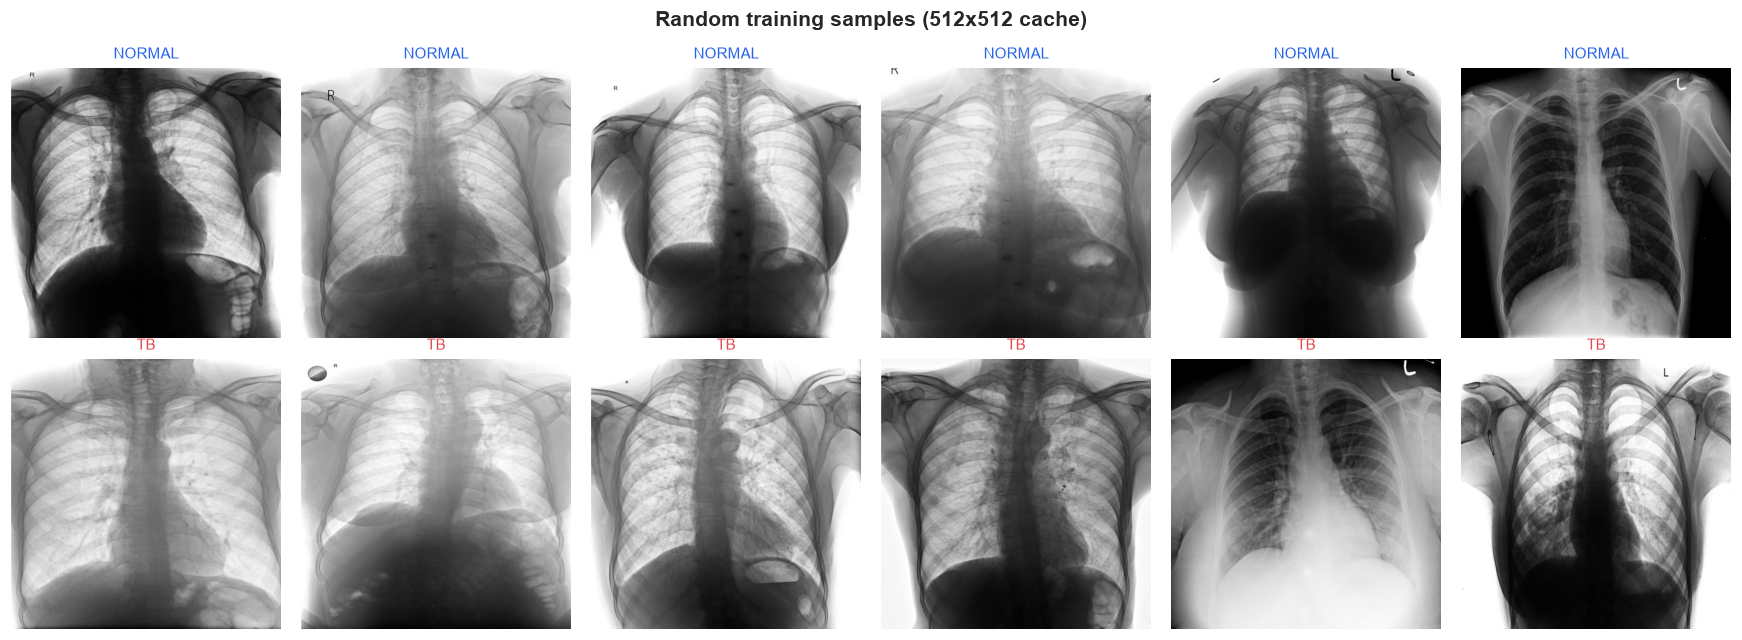

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, cls in enumerate(CLASSES):
    picks = data[(data["class"] == cls) & (data.folder == "train")].sample(6, random_state=SEED)
    for ax, p in zip(axes[r], picks.path):
        ax.imshow(tvio.decode_image(tvio.read_file(str(ROOT / p)), mode=tvio.ImageReadMode.GRAY)[0], cmap="gray")
        ax.set_title(cls.upper(), color="#E5484D" if cls == "tb" else "#2563EB", fontsize=10); ax.axis("off")
fig.suptitle("Random training samples (512x512 cache)", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

## 4. Intensity statistics and the average X-ray per class

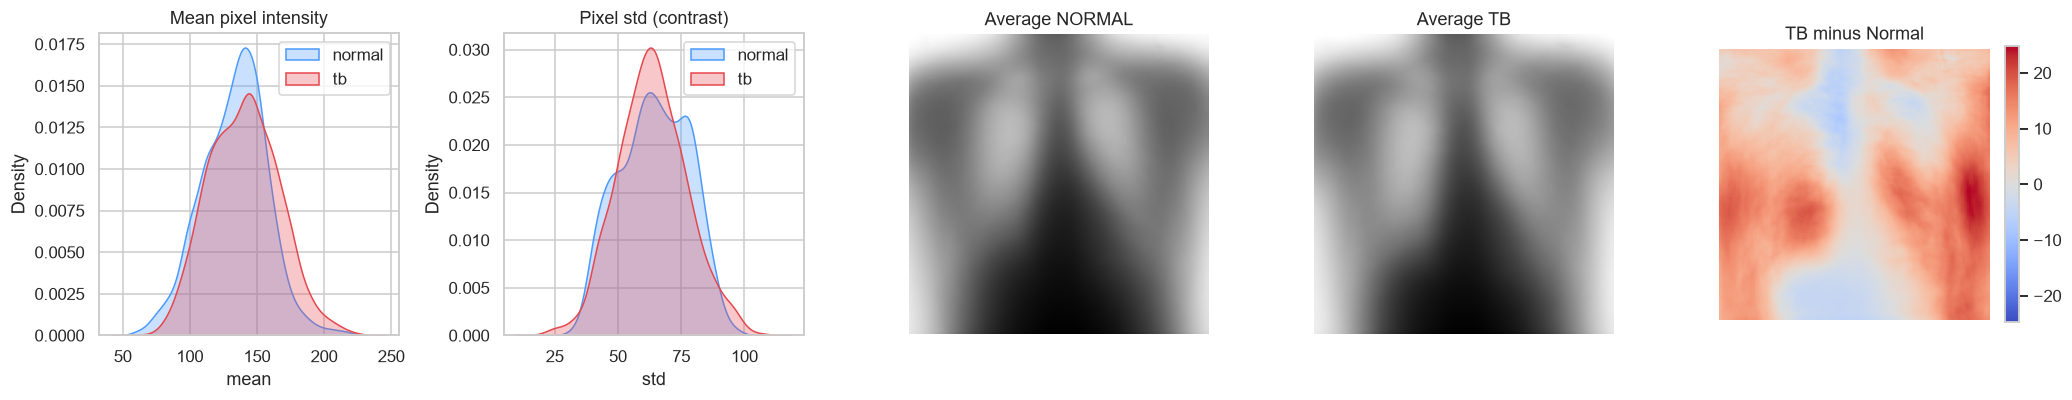

class       normal      tb
mean count  1500.0  1500.0
     mean    133.2   140.2
     std      24.3    26.0
     min      59.3    60.7
     25%     116.2   120.6
     50%     135.4   140.6
     75%     149.4   158.4
     max     217.8   227.4
std  count  1500.0  1500.0
     mean     64.2    63.4
     std      13.6    13.6
     min      31.6    19.8
     25%      53.8    54.1
     50%      64.5    63.0
     75%      75.6    72.3
     max      98.0   108.6


In [5]:
def load_small(path, size=128):
    x = tvio.decode_image(tvio.read_file(str(ROOT / path)), mode=tvio.ImageReadMode.GRAY).float()[None]
    return F.interpolate(x, size=(size, size), mode="area")[0, 0].numpy()

stat_sample = data.groupby("class").sample(1500, random_state=SEED)
with ThreadPoolExecutor(12) as pool:
    smalls = list(pool.map(load_small, stat_sample.path))
stack = np.stack(smalls)
stat_sample = stat_sample.assign(mean=stack.mean((1, 2)), std=stack.std((1, 2)))

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for cls, color in zip(CLASSES, ["#4C9AFF", "#E5484D"]):
    sel = (stat_sample["class"] == cls).to_numpy()
    sns.kdeplot(stat_sample[sel]["mean"], ax=axes[0], label=cls, color=color, fill=True, alpha=0.3)
    sns.kdeplot(stat_sample[sel]["std"], ax=axes[1], label=cls, color=color, fill=True, alpha=0.3)
axes[0].set(title="Mean pixel intensity"); axes[0].legend()
axes[1].set(title="Pixel std (contrast)"); axes[1].legend()
mean_normal = stack[(stat_sample["class"] == "normal").to_numpy()].mean(0)
mean_tb = stack[(stat_sample["class"] == "tb").to_numpy()].mean(0)
axes[2].imshow(mean_normal, cmap="gray"); axes[2].set_title("Average NORMAL")
axes[3].imshow(mean_tb, cmap="gray"); axes[3].set_title("Average TB")
diff = mean_tb - mean_normal
lim = np.abs(diff).max()
im = axes[4].imshow(diff, cmap="coolwarm", vmin=-lim, vmax=lim); axes[4].set_title("TB minus Normal")
plt.colorbar(im, ax=axes[4], fraction=0.046)
for ax in axes[2:]: ax.axis("off")
plt.tight_layout(); plt.show()
print(stat_sample.groupby("class")[["mean", "std"]].describe().round(1).T)

## 5. Duplicate & near-duplicate check (data-leak audit)

In [6]:
import hashlib

def fingerprints(path):
    raw = (ROOT / path).read_bytes()
    x = tvio.decode_image(torch.frombuffer(bytearray(raw), dtype=torch.uint8), mode=tvio.ImageReadMode.GRAY).float()[None]
    return hashlib.md5(raw).hexdigest(), F.interpolate(x, size=(32, 32), mode="area").flatten()

t0 = time.time()
with ThreadPoolExecutor(16) as pool:
    fp = list(pool.map(fingerprints, data.path))
data["md5"] = [a for a, _ in fp]
thumbs = torch.stack([b for _, b in fp])
thumbs = thumbs - thumbs.mean(1, keepdim=True)
thumbs = (thumbs / thumbs.norm(dim=1, keepdim=True)).to(DEVICE)
print(f"Fingerprinted {len(data):,} images in {time.time() - t0:.0f}s")

dupe_md5 = data[data.duplicated("md5", keep=False)]
groups = dupe_md5.groupby("md5").agg(n=("path", "size"), folders=("folder", lambda s: "+".join(sorted(set(s)))),
                                     n_labels=("class", "nunique"))
print(f"Exact duplicate files: {len(dupe_md5)} images in {len(groups)} groups")
print("Groups by folders involved:", groups.folders.value_counts().to_dict())
print(f"Groups whose copies carry DIFFERENT labels (label noise): {(groups.n_labels > 1).sum()}")

Fingerprinted 16,807 images in 10s
Exact duplicate files: 128 images in 64 groups
Groups by folders involved: {'train': 41, 'train+val': 22, 'val': 1}
Groups whose copies carry DIFFERENT labels (label noise): 1


C:\Users\Veer Pratap Singh\AppData\Local\Temp\ipykernel_28236\1752839995.py:5: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  sim = thumbs[torch.from_numpy(~is_tr).to(DEVICE)] @ thumbs[torch.from_numpy(is_tr).to(DEVICE)].T


similarity >= 0.9  :  2809 val images | label agrees with train twin: 0.66
similarity >= 0.95 :   712 val images | label agrees with train twin: 0.72
similarity >= 0.97 :    57 val images | label agrees with train twin: 0.88
similarity >= 0.98 :    24 val images | label agrees with train twin: 0.92
similarity >= 0.99 :    22 val images | label agrees with train twin: 0.95
similarity >= 0.999:    22 val images | label agrees with train twin: 0.95

Near-duplicates of a training image (similarity >= 0.98): 24 / 3362 (0.71%)


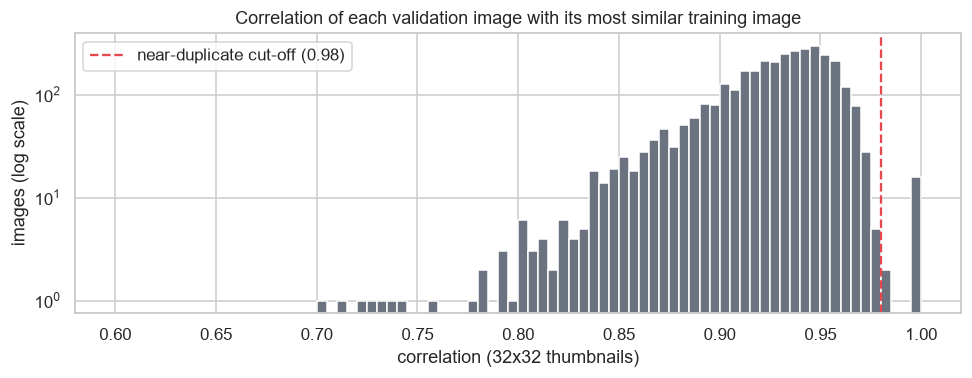

In [7]:
# Near duplicates: highest correlation between each validation image and any training image.
is_tr = (data.folder == "train").to_numpy()
tr = data[is_tr].reset_index(drop=True)
va = data[~is_tr].reset_index(drop=True)
sim = thumbs[torch.from_numpy(~is_tr).to(DEVICE)] @ thumbs[torch.from_numpy(is_tr).to(DEVICE)].T
best_sim, best_idx = (t.cpu().numpy() for t in sim.max(1))
va["nearest_train_sim"] = best_sim
va["nearest_train_path"] = tr.path.to_numpy()[best_idx]
va["nearest_train_class"] = tr["class"].to_numpy()[best_idx]

for t in [0.90, 0.95, 0.97, 0.98, 0.99, 0.999]:
    m = va.nearest_train_sim >= t
    print(f"similarity >= {t:<5}: {m.sum():5d} val images | label agrees with train twin: "
          f"{(va['class'][m] == va.nearest_train_class[m]).mean():.2f}")

SIM = 0.98   # natural gap in the distribution: true copies sit at ~1.0, look-alikes below 0.98
leaky = va[va.nearest_train_sim >= SIM]
print(f"\nNear-duplicates of a training image (similarity >= {SIM}): {len(leaky)} / {len(va)} ({len(leaky) / len(va):.2%})")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(best_sim, bins=np.linspace(0.6, 1.0, 81), color="#6B7280")
ax.axvline(SIM, color="#E5484D", ls="--", label=f"near-duplicate cut-off ({SIM})")
ax.set_yscale("log")
ax.set(title="Correlation of each validation image with its most similar training image",
       xlabel="correlation (32x32 thumbnails)", ylabel="images (log scale)")
ax.legend(); plt.tight_layout(); plt.show()

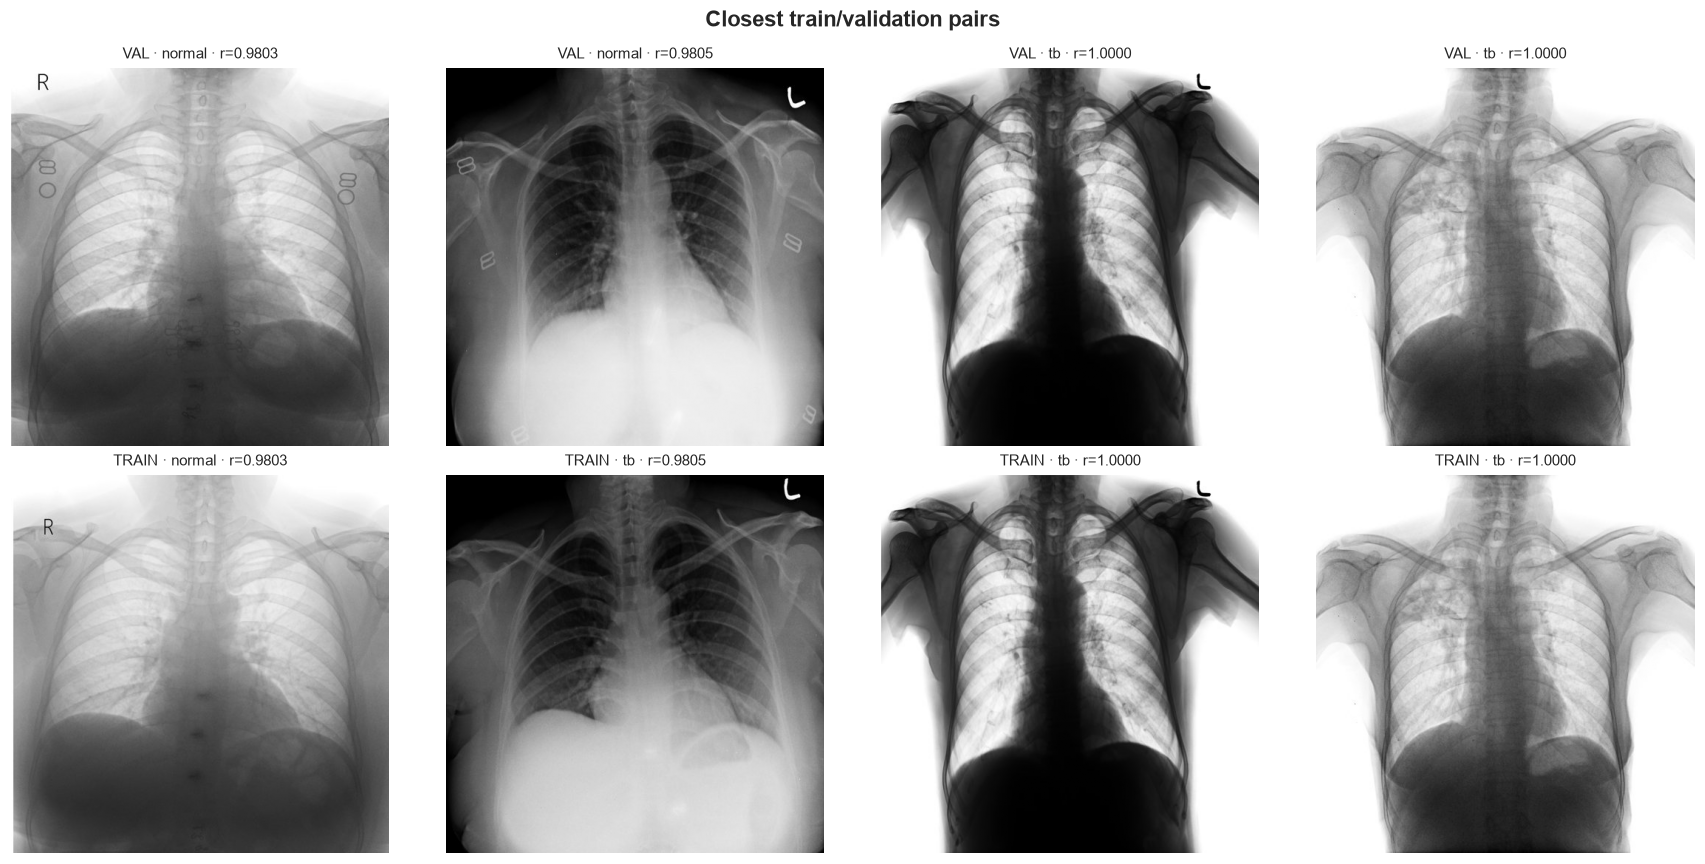

In [8]:
if len(leaky):
    show = leaky.sort_values("nearest_train_sim").head(4)
    fig, axes = plt.subplots(2, len(show), figsize=(4 * len(show), 8))
    axes = np.array(axes).reshape(2, -1)
    for i, (_, r) in enumerate(show.iterrows()):
        for row, (p, name) in enumerate([(r.path, "VAL"), (r.nearest_train_path, "TRAIN")]):
            axes[row, i].imshow(tvio.decode_image(tvio.read_file(str(ROOT / p)), mode=tvio.ImageReadMode.GRAY)[0], cmap="gray")
            axes[row, i].set_title(f"{name} · {r['class'] if name == 'VAL' else r.nearest_train_class} · r={r.nearest_train_sim:.4f}", fontsize=10); axes[row, i].axis("off")
    fig.suptitle("Closest train/validation pairs", weight="bold"); plt.tight_layout(); plt.show()

## 6. Freeze the splits

In [9]:
from sklearn.model_selection import train_test_split

va["is_leaky"] = va.nearest_train_sim >= SIM
clean = va[~va.is_leaky]
target_test = len(va) // 2
test_frac = min(target_test / len(clean), 1.0)
val_part, test_part = train_test_split(clean, test_size=test_frac, stratify=clean.label, random_state=SEED)
val_part = pd.concat([val_part, va[va.is_leaky]])

splits = pd.concat([
    tr.assign(split="train", near_dup_of_train=False),
    val_part.assign(split="val", near_dup_of_train=val_part.is_leaky),
    test_part.assign(split="test", near_dup_of_train=False),
])[["path", "label", "class", "split", "near_dup_of_train", "md5"]].reset_index(drop=True)

# Remove exact duplicate files that would cross splits (keep the train copy).
cross = splits.groupby("md5").split.nunique()
cross_md5 = set(cross[cross > 1].index)
dropped = splits[splits.md5.isin(cross_md5) & (splits.split != "train")]
splits = splits.drop(dropped.index).reset_index(drop=True)
print(f"Dropped {len(dropped)} non-train copies of files that also exist in train.")

(ROOT / "splits").mkdir(exist_ok=True)
splits.drop(columns="md5").to_csv(ROOT / "splits" / "splits.csv", index=False)
summary = splits.groupby(["split", "class"]).size().unstack()
summary["total"] = summary.sum(1)
display(summary)
print("Saved ->", ROOT / "splits" / "splits.csv")

Dropped 22 non-train copies of files that also exist in train.


C:\Users\Veer Pratap Singh\AppData\Local\Temp\ipykernel_28236\2893242154.py:26: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  summary["total"] = summary.sum(1)


class,normal,tb,total
split,,,
test,861,820,1681
train,6860,6585,13445
val,850,809,1659


Saved -> F:\Projects\pulmoSight\TB Project\splits\splits.csv
